# Практика 1. Обработка SAR-изображения `sar_1_gray.jpg`

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

## 1. Загрузка изображения в оттенках серого

Размер (h, w): (400, 600)
Тип данных: uint8
min / max / mean / std: 0 / 255 / 74.94 / 43.66


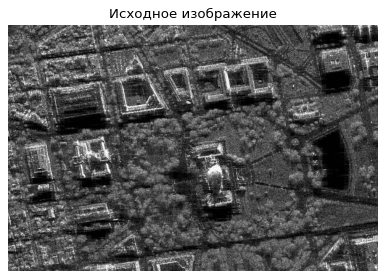

In [2]:
image_gray = cv2.imread('sar_1_gray.jpg', cv2.IMREAD_GRAYSCALE)

print("Размер (h, w):", image_gray.shape)
print("Тип данных:", image_gray.dtype)
print("min / max / mean / std: {} / {} / {:.2f} / {:.2f}".format(
    image_gray.min(), image_gray.max(), image_gray.mean(), image_gray.std()))

plt.figure(figsize=(6, 4))
plt.imshow(image_gray, cmap='gray', vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis('off')
plt.show()

## 2. Гистограмма

Всего пикселей по гистограмме: 240000 из 240000
Самый частый уровень яркости: 1 (пикселей: 3786)


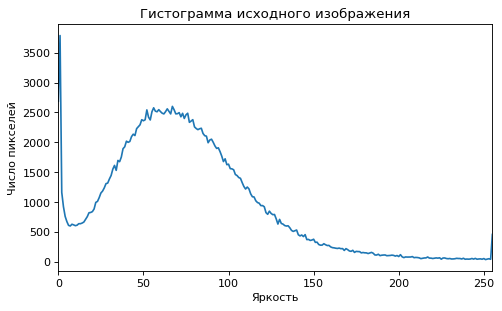

In [3]:
histSize = 256
histRange = (0, 256)

hist = cv2.calcHist([image_gray], [0], None, [histSize], histRange, accumulate=False)

print("Всего пикселей по гистограмме:", int(hist.sum()), "из", image_gray.size)
print("Самый частый уровень яркости:", int(hist.argmax()), "(пикселей: {})".format(int(hist.max())))

plt.figure(figsize=(7, 4))
plt.plot(hist)
plt.xlim([0, 255])
plt.title("Гистограмма исходного изображения")
plt.xlabel("Яркость")
plt.ylabel("Число пикселей")
plt.show()

## 3. Гамма-коррекция

$$I_{out} = 255 \cdot \left(\frac{I_{in}}{255}\right)^{\gamma}$$

γ < 1 осветляет изображение, γ > 1 затемняет.

Средняя яркость: исходное = 74.94, gamma=0.5 -> 131.09, gamma=2.0 -> 29.49


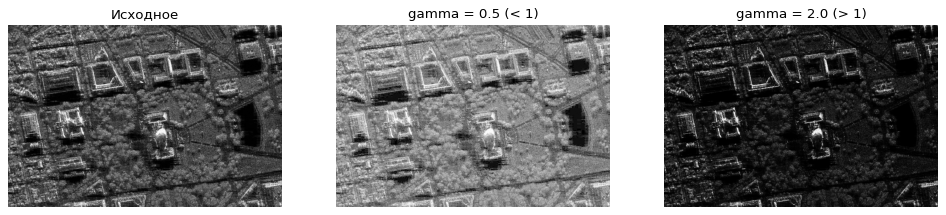

In [4]:
def gamma_correction(img, gamma):
    """Гамма-коррекция uint8-изображения (собственная реализация)."""
    norm = img.astype(np.float64) / 255.0
    out = np.power(norm, gamma) * 255.0
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

gamma_low = 0.5    # gamma < 1
gamma_high = 2.0   # gamma > 1

img_gamma_low = gamma_correction(image_gray, gamma_low)
img_gamma_high = gamma_correction(image_gray, gamma_high)

print("Средняя яркость: исходное = {:.2f}, gamma={} -> {:.2f}, gamma={} -> {:.2f}".format(
    image_gray.mean(), gamma_low, img_gamma_low.mean(), gamma_high, img_gamma_high.mean()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, im, title in zip(axes,
                         [image_gray, img_gamma_low, img_gamma_high],
                         ["Исходное", "gamma = {} (< 1)".format(gamma_low), "gamma = {} (> 1)".format(gamma_high)]):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.show()

## 4. Сравнение исходного и скорректированного изображений: MSE, SSIM

In [5]:
print("{:<22}{:>12}{:>10}".format("Сравнение", "MSE", "SSIM"))
for name, im in [("исходное vs gamma={}".format(gamma_low), img_gamma_low),
                 ("исходное vs gamma={}".format(gamma_high), img_gamma_high)]:
    mse = mean_squared_error(image_gray, im)
    ssim = structural_similarity(image_gray, im, data_range=255)
    print("{:<22}{:>12.2f}{:>10.4f}".format(name, mse, ssim))

Сравнение                      MSE      SSIM
исходное vs gamma=0.5      3310.21    0.7854
исходное vs gamma=2.0      2343.93    0.5352


## 5. Статистическая цветокоррекция на основе статистики `eq_gray`

Сначала `eq_gray` — результат эквализации гистограммы (собственная реализация, без `cv2.equalizeHist`):

$$LUT(k) = \mathrm{round}\left(255 \cdot \frac{CDF(k) - CDF_{min}}{N - CDF_{min}}\right)$$

Затем яркость исходного изображения приводится к среднему и стандартному отклонению `eq_gray`:

$$I_{out} = \frac{I_{in} - \mu_{in}}{\sigma_{in}} \cdot \sigma_{eq} + \mu_{eq}$$

Изображение                           mean       std
Исходное                             74.94     43.66
eq_gray (эталон)                    127.03     74.27
После стат. цветокоррекции          123.59     65.27


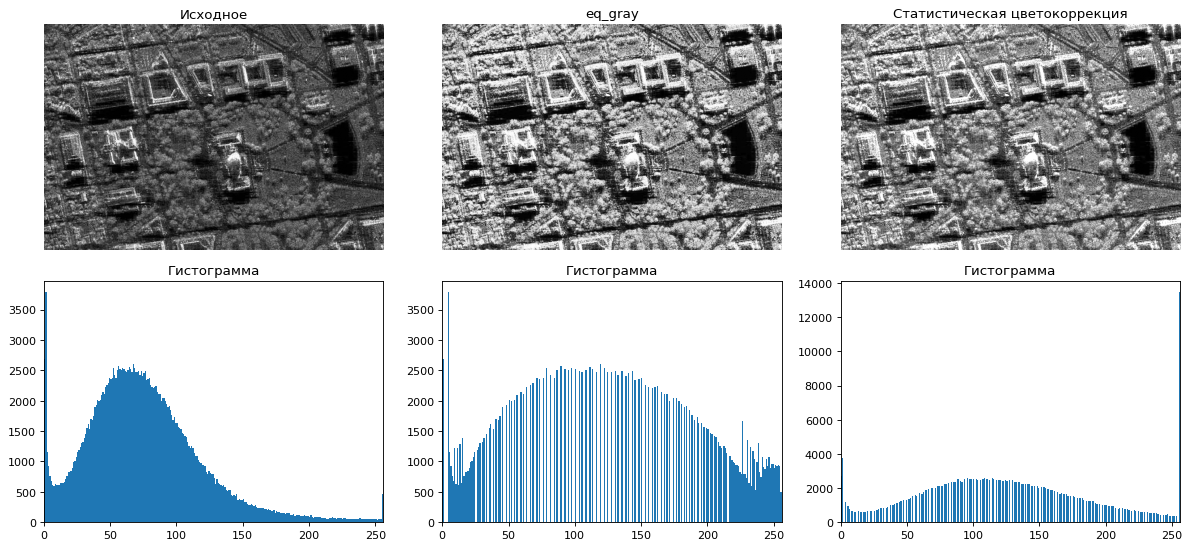

In [6]:
def equalize_hist(img):
    """Эквализация гистограммы uint8-изображения (собственная реализация)."""
    hist = np.bincount(img.ravel(), minlength=256)
    cdf = hist.cumsum()
    cdf_min = cdf[cdf > 0].min()
    lut = np.round((cdf - cdf_min) / (img.size - cdf_min) * 255.0)
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    return lut[img]


def statistical_correction(img, ref):
    """Приведение mean и std изображения img к mean и std эталона ref."""
    img_f = img.astype(np.float64)
    out = (img_f - img_f.mean()) / img_f.std() * ref.std() + ref.mean()
    return np.clip(np.round(out), 0, 255).astype(np.uint8)


eq_gray = equalize_hist(image_gray)
stat_gray = statistical_correction(image_gray, eq_gray)

print("{:<32}{:>10}{:>10}".format("Изображение", "mean", "std"))
for name, im in [("Исходное", image_gray),
                 ("eq_gray (эталон)", eq_gray),
                 ("После стат. цветокоррекции", stat_gray)]:
    print("{:<32}{:>10.2f}{:>10.2f}".format(name, im.mean(), im.std()))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, (im, title) in enumerate([(image_gray, "Исходное"),
                                 (eq_gray, "eq_gray"),
                                 (stat_gray, "Статистическая цветокоррекция")]):
    axes[0, i].imshow(im, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis('off')
    axes[1, i].hist(im.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_xlim([0, 256])
    axes[1, i].set_title("Гистограмма")
plt.tight_layout()
plt.show()

## 6. Пороговая фильтрация с различными параметрами

In [7]:
def show_grid(images, titles, cols=4):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, title in zip(axes, images, titles):
        ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()


def white_percent(im):
    """Доля пикселей с максимальной яркостью 255, %."""
    return 100.0 * np.count_nonzero(im == 255) / im.size

**6.1. Глобальный порог `THRESH_BINARY` при разных значениях порога**

Порог T        Белых пикселей, %
50                         70.49
100                        23.19
150                         5.45
200                         1.60


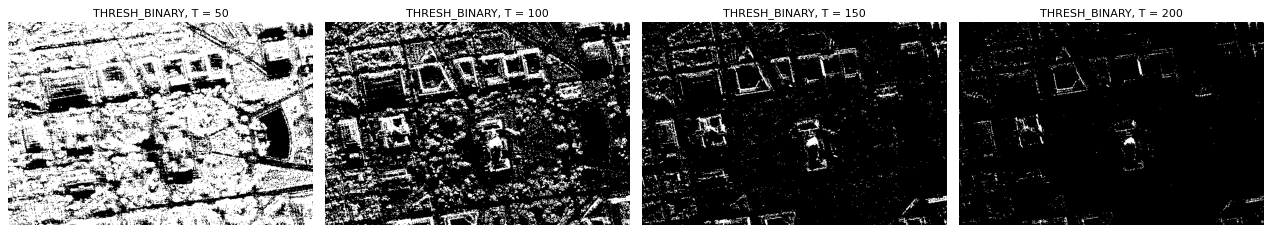

In [8]:
images, titles = [], []
print("{:<10}{:>22}".format("Порог T", "Белых пикселей, %"))
for T in [50, 100, 150, 200]:
    _, th = cv2.threshold(image_gray, T, 255, cv2.THRESH_BINARY)
    print("{:<10}{:>22.2f}".format(T, white_percent(th)))
    images.append(th)
    titles.append("THRESH_BINARY, T = {}".format(T))
show_grid(images, titles)

**6.2. Разные типы пороговой обработки при T = 100**

Тип (T = 100)               mean
THRESH_BINARY              59.13
THRESH_BINARY_INV         195.87
THRESH_TRUNC               66.75
THRESH_TOZERO              31.38
THRESH_TOZERO_INV          43.56


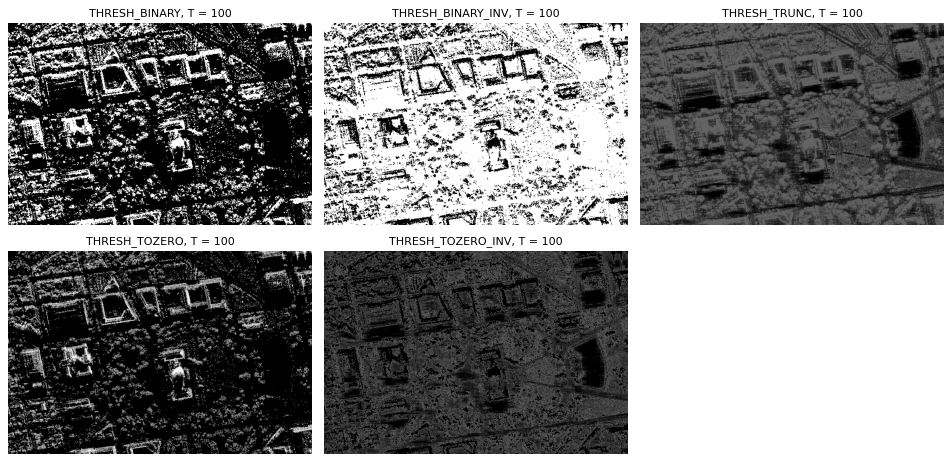

In [9]:
T = 100
types = [("THRESH_BINARY", cv2.THRESH_BINARY),
         ("THRESH_BINARY_INV", cv2.THRESH_BINARY_INV),
         ("THRESH_TRUNC", cv2.THRESH_TRUNC),
         ("THRESH_TOZERO", cv2.THRESH_TOZERO),
         ("THRESH_TOZERO_INV", cv2.THRESH_TOZERO_INV)]

images, titles = [], []
print("{:<20}{:>12}".format("Тип (T = {})".format(T), "mean"))
for name, flag in types:
    _, th = cv2.threshold(image_gray, T, 255, flag)
    print("{:<20}{:>12.2f}".format(name, th.mean()))
    images.append(th)
    titles.append("{}, T = {}".format(name, T))
show_grid(images, titles, cols=3)

**6.3. Автоматический порог по методу Оцу**

Порог, найденный методом Оцу: 85
Белых пикселей: 35.00%


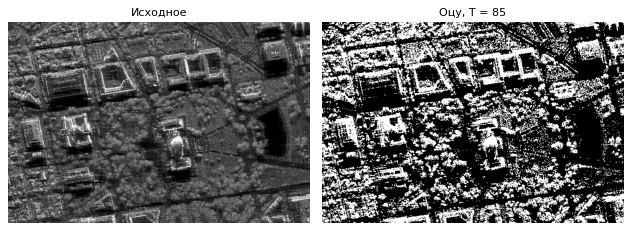

In [10]:
otsu_T, th_otsu = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Порог, найденный методом Оцу: {:.0f}".format(otsu_T))
print("Белых пикселей: {:.2f}%".format(white_percent(th_otsu)))

show_grid([image_gray, th_otsu], ["Исходное", "Оцу, T = {:.0f}".format(otsu_T)], cols=2)

**6.4. Адаптивный порог: метод вычисления порога и размер окна (blockSize), C = 2**

Метод           blockSize     Белых пикселей, %
MEAN_C                 11                 47.13
MEAN_C                 51                 46.02
GAUSSIAN_C             11                 49.07
GAUSSIAN_C             51                 45.34


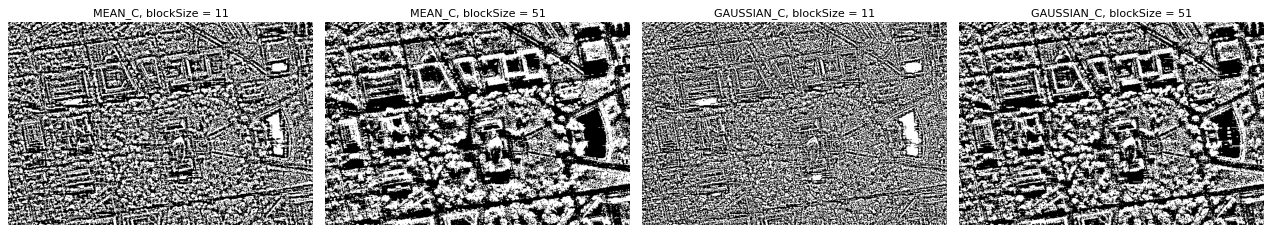

In [11]:
methods = [("MEAN_C", cv2.ADAPTIVE_THRESH_MEAN_C),
           ("GAUSSIAN_C", cv2.ADAPTIVE_THRESH_GAUSSIAN_C)]

images, titles = [], []
print("{:<14}{:>11}{:>22}".format("Метод", "blockSize", "Белых пикселей, %"))
for name, method in methods:
    for block in [11, 51]:
        th = cv2.adaptiveThreshold(image_gray, 255, method, cv2.THRESH_BINARY, block, 2)
        print("{:<14}{:>11}{:>22.2f}".format(name, block, white_percent(th)))
        images.append(th)
        titles.append("{}, blockSize = {}".format(name, block))
show_grid(images, titles)